# Start

In [97]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

In [98]:
data = 'credit_risk_scoring_data.csv'


In [99]:
df = pd.read_csv(data)
df.head()


,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


# Data Preparation and Cleaning

1. make columns name lowercase
2. Re-encoding the categorical variables - 
    The columns "status", "home", "marital", "records" and "job" are categorical, but in the file they are encoded as numbers. For example, status is 1, 2 or 0. That's not very intuitive, so we decode them into strings.
3. Replace the missing numerical variables with NaN
4. Removing the one unknown status


In [100]:
# 1. make columns name lowercase
df.columns = df.columns.str.lower()

In [101]:
# 2. Re-encoding the categorical variables
status_values = {
    1: 'ok',
    2: 'default',
    0: 'unk'
}

df.status = df.status.map(status_values)

home_values = {
    1: 'rent',
    2: 'owner',
    3: 'private',
    4: 'ignore',
    5: 'parents',
    6: 'other',
    0: 'unk'
}

df.home = df.home.map(home_values)

marital_values = {
    1: 'single',
    2: 'married',
    3: 'widow',
    4: 'separated',
    5: 'divorced',
    0: 'unk'
}

df.marital = df.marital.map(marital_values)

records_values = {
    1: 'no',
    2: 'yes',
    0: 'unk'
}

df.records = df.records.map(records_values)

job_values = {
    1: 'fixed',
    2: 'partime',
    3: 'freelance',
    4: 'others',
    0: 'unk'
}

df.job = df.job.map(job_values)

In [102]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129,0,0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131,0,0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200,3000,0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182,2500,0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107,0,0,310,910


In [103]:
#3. Replace the missing numerical variables with NaN
for c in ['income', 'assets', 'debt']:
    df[c] = df[c].replace(to_replace=99999999, value=np.nan)

In [104]:
#4. Removing the unknown status
df[df.status == 'unk']

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
3309,unk,10,private,60,25,single,no,fixed,35,148.0,3000.0,0.0,1500,1888


In [105]:
df = df[df.status != 'unk'].reset_index(drop=True)

# Dataset train/validation/test split

1. split the dataset into df_full_train 80% + df_test 20% , then df_train 60% + df_val 20%
2. prepare target variable - encode status: 0 for ok, 1 for default.


In [106]:
#1. split the dataset into df_full_train 80% + df_test 20% , then df_train 60% + df_val 20%
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=11)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=11)

In [107]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [108]:
#2. prepare target variable - encode status: 0 for ok, 1 for default.

y_train = (df_train.status == 'default').astype('int').values
y_val = (df_val.status == 'default').astype('int').values
y_test = (df_test.status == 'default').astype('int').values

In [109]:
del df_train['status']
del df_val['status']
del df_test['status']

# Decision tree

## train the decision tree

In [110]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.tree import export_text

In [111]:
train_dicts = df_train.fillna(0).to_dict(orient='records')
val_dicts = df_val.fillna(0).to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

In [112]:
dt = DecisionTreeClassifier(max_depth=5)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

In [113]:
y_pred_train = dt.predict_proba(X_train)[:, 1]
auc_train = roc_auc_score(y_train, y_pred_train)
print('train:', auc_train)

y_pred_val = dt.predict_proba(X_val)[:, 1]
auc_val = roc_auc_score(y_val, y_pred_val)
print('val:', auc_val)

train: 0.8433781899611289
val: 0.7669377103969388


In [114]:
print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- records=no <= 0.50
|   |--- seniority <= 6.50
|   |   |--- amount <= 862.50
|   |   |   |--- seniority <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- seniority >  0.50
|   |   |   |   |--- income <= 50.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- income >  50.50
|   |   |   |   |   |--- class: 0
|   |   |--- amount >  862.50
|   |   |   |--- assets <= 8250.00
|   |   |   |   |--- job=fixed <= 0.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- job=fixed >  0.50
|   |   |   |   |   |--- class: 1
|   |   |   |--- assets >  8250.00
|   |   |   |   |--- income <= 132.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- income >  132.50
|   |   |   |   |   |--- class: 0
|   |--- seniority >  6.50
|   |   |--- income <= 103.50
|   |   |   |--- assets <= 4500.00
|   |   |   |   |--- time <= 54.00
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- time >  54.00
|   |   |   |   |   |--- class: 1
|   |   |   |--- assets >  4500.00
|   |   |   |   |--- i

## Find the best max_depth - with generalization
-- by plotting the train and validation AUC scores for depths from 1 to 10.

In [115]:
scores = []

for depth in range(1, 21):
    dt = DecisionTreeClassifier(max_depth=depth)
    dt.fit(X_train, y_train)

    y_pred_train = dt.predict_proba(X_train)[:, 1]
    y_pred_val = dt.predict_proba(X_val)[:, 1]

    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)

    scores.append((depth, auc_train, auc_val))

In [116]:
for depth, auc_train, auc_val in scores:
    print(
        f'depth: {depth:2d} | '
        f'train: {auc_train:.4f} | '
        f'val: {auc_val:.4f} | '
        f'gap: {((auc_train - auc_val)*100):.4f}'
    )

    best = max(scores, key=lambda x: x[2])

print()
print('Best depth:', best[0])
print('Best train AUC:', best[1])
print('Best validation AUC:', best[2])

depth:  1 | train: 0.6283 | val: 0.6059 | gap: 2.2402
depth:  2 | train: 0.7055 | val: 0.6685 | gap: 3.6973
depth:  3 | train: 0.7761 | val: 0.7389 | gap: 3.7194
depth:  4 | train: 0.8164 | val: 0.7613 | gap: 5.5147
depth:  5 | train: 0.8434 | val: 0.7665 | gap: 7.6882
depth:  6 | train: 0.8745 | val: 0.7508 | gap: 12.3711
depth:  7 | train: 0.9000 | val: 0.7553 | gap: 14.4706
depth:  8 | train: 0.9246 | val: 0.7398 | gap: 18.4797
depth:  9 | train: 0.9476 | val: 0.6969 | gap: 25.0683
depth: 10 | train: 0.9639 | val: 0.6853 | gap: 27.8580
depth: 11 | train: 0.9781 | val: 0.6795 | gap: 29.8542
depth: 12 | train: 0.9874 | val: 0.6859 | gap: 30.1513
depth: 13 | train: 0.9936 | val: 0.6704 | gap: 32.3210
depth: 14 | train: 0.9965 | val: 0.6726 | gap: 32.3977
depth: 15 | train: 0.9983 | val: 0.6636 | gap: 33.4680
depth: 16 | train: 0.9996 | val: 0.6633 | gap: 33.6289
depth: 17 | train: 0.9999 | val: 0.6574 | gap: 34.2560
depth: 18 | train: 1.0000 | val: 0.6528 | gap: 34.7162
depth: 19 | tra

In [117]:
import matplotlib.pyplot as plt

depths = [x[0] for x in scores]
train_auc = [x[1] for x in scores]
val_auc = [x[2] for x in scores]

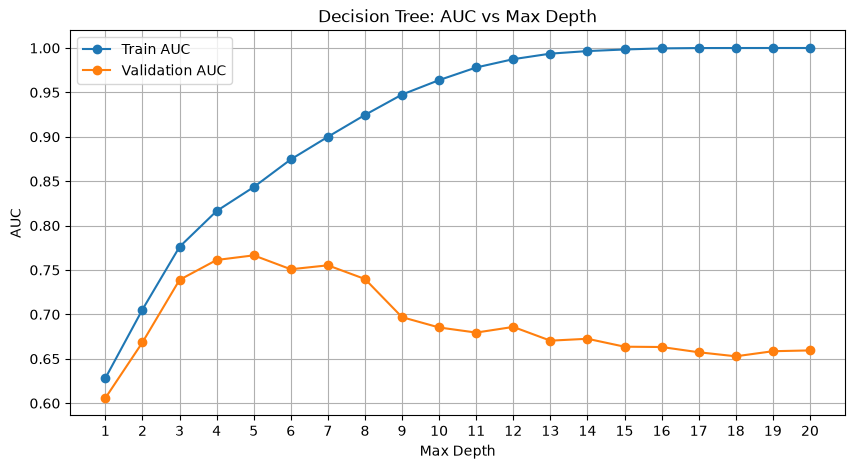

In [118]:
plt.figure(figsize=(10, 5))

plt.plot(depths, train_auc, label='Train AUC', marker='o')
plt.plot(depths, val_auc, label='Validation AUC', marker='o')

plt.xlabel('Max Depth')
plt.ylabel('AUC')
plt.title('Decision Tree: AUC vs Max Depth')

plt.xticks(depths)
plt.legend()
plt.grid()

plt.show()

## Investigate the most important features

In [119]:
importance = pd.Series(
    dt.feature_importances_,
    index=dv.get_feature_names_out()
)

importance.sort_values(ascending=False)

income               0.181653
price                0.112936
amount               0.104173
age                  0.095968
seniority            0.092011
records=yes          0.090909
assets               0.083260
job=partime          0.065043
expenses             0.043201
time                 0.026930
debt                 0.021367
home=rent            0.020849
job=fixed            0.010617
home=owner           0.008391
home=parents         0.008378
marital=separated    0.005700
marital=married      0.005511
home=other           0.004795
marital=single       0.003861
home=private         0.003395
job=others           0.003367
job=freelance        0.002613
marital=divorced     0.002551
home=ignore          0.001368
marital=widow        0.001155
home=unk             0.000000
job=unk              0.000000
marital=unk          0.000000
records=no           0.000000
dtype: float64

In [120]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    dt,
    X_val,
    y_val,
    scoring='roc_auc',
    n_repeats=10,
    random_state=42
)

importance = pd.Series(
    result.importances_mean,
    index=dv.get_feature_names_out()
)

importance.sort_values(ascending=False)

records=yes          0.042031
job=partime          0.039327
amount               0.035221
assets               0.025524
income               0.024602
seniority            0.014601
price                0.013899
time                 0.008747
age                  0.007660
home=rent            0.006823
home=parents         0.003303
marital=single       0.003245
home=private         0.002844
job=others           0.002189
marital=married      0.001521
home=owner           0.000345
job=unk              0.000000
home=ignore          0.000000
marital=unk          0.000000
marital=widow        0.000000
home=unk             0.000000
records=no           0.000000
expenses            -0.000606
marital=separated   -0.000611
marital=divorced    -0.000699
home=other          -0.001822
job=freelance       -0.001932
job=fixed           -0.003430
debt                -0.004621
dtype: float64

## Model Tuning

1. select max-depth
2. add min_samples_leaf

In [121]:
depths = [1, 2, 3, 4, 5, 6, 10, 15, 20, None]

for depth in depths: 
    dt = DecisionTreeClassifier(max_depth=depth)
    dt.fit(X_train, y_train)
    
    y_pred = dt.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    
    print('%4s -> %.3f' % (depth, auc))

   1 -> 0.606
   2 -> 0.669
   3 -> 0.739
   4 -> 0.761
   5 -> 0.766
   6 -> 0.761
  10 -> 0.695
  15 -> 0.666
  20 -> 0.657
None -> 0.649


In [122]:
scores = []

for depth in [3,4, 5, 6, 7]:
    for s in [1, 5, 10, 15, 20, 500, 100, 200]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=s)
        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        
        scores.append((depth, s, auc))

In [123]:
columns = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['auc'])
df_scores_pivot.round(3)

auc                            
max_depth             3      4      5      6      7
min_samples_leaf                                   
1                 0.739  0.761  0.767  0.747  0.748
5                 0.739  0.761  0.768  0.762  0.759
10                0.739  0.761  0.762  0.778  0.765
15                0.738  0.764  0.772  0.785  0.780
20                0.736  0.761  0.774  0.774  0.780
100               0.736  0.756  0.763  0.776  0.780
200               0.729  0.747  0.759  0.768  0.768
500               0.680  0.680  0.680  0.680  0.680

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

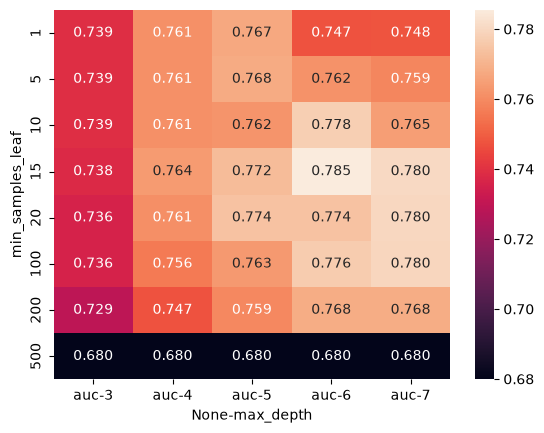

In [124]:
sns.heatmap(df_scores_pivot, annot=True, fmt=".3f")


# Random Forest 


## Tuning including min_samples_leaf


In [125]:

from sklearn.ensemble import RandomForestClassifier

scores = []

for d in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=d,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d, n, auc))

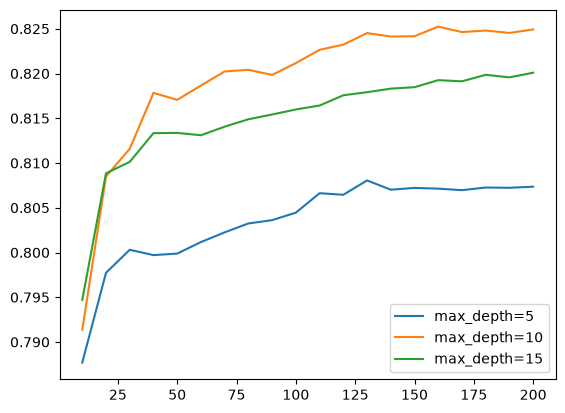

In [126]:


columns = ['max_depth', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

for d in [5, 10, 15]:
    df_subset = df_scores[df_scores.max_depth == d]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             label='max_depth=%d' % d)

plt.legend()

In [127]:
max_depth = 10


In [128]:

scores = []

for s in [1, 3, 5, 10, 50]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=max_depth,
                                    min_samples_leaf=s,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((s, n, auc))

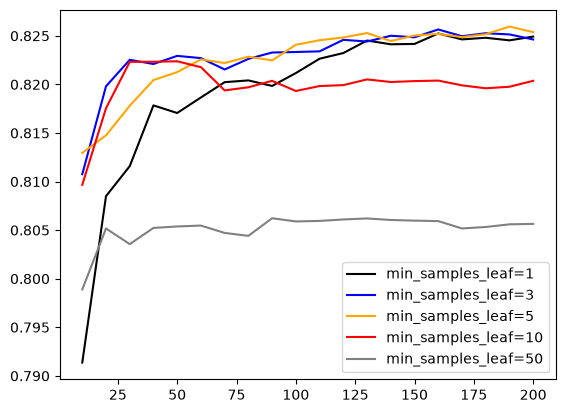

In [129]:
columns = ['min_samples_leaf', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

colors = ['black', 'blue', 'orange', 'red', 'grey']
values = [1, 3, 5, 10, 50]

for s, col in zip(values, colors):
    df_subset = df_scores[df_scores.min_samples_leaf == s]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             color=col,
             label='min_samples_leaf=%d' % s)

plt.legend()

In [130]:
min_samples_leaf = 3

In [ ]:
# yields the random forest model with the best hyperparameters

rf = RandomForestClassifier(n_estimators=200,
                            max_depth=max_depth,
                            min_samples_leaf=min_samples_leaf,
                            random_state=1)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

# XGBoost

In [132]:
import xgboost as xgb

In [133]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

In [134]:
xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'nthread': 8,

    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=10)

In [135]:
y_pred = model.predict(dval)
auc = roc_auc_score(y_val, y_pred)
print('AUC = %.3f' % auc)

AUC = 0.816


In [136]:
xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'nthread': 8,

    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=10)

In [137]:
y_pred = model.predict(dval)
roc_auc_score(y_val, y_pred)

0.8156256811411687

## performance monitoring

In [138]:
watchlist = [(dtrain, 'train'), (dval, 'val')]

In [139]:
%%capture output

xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [140]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))

    columns = ['num_iter', 'train_auc', 'val_auc']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

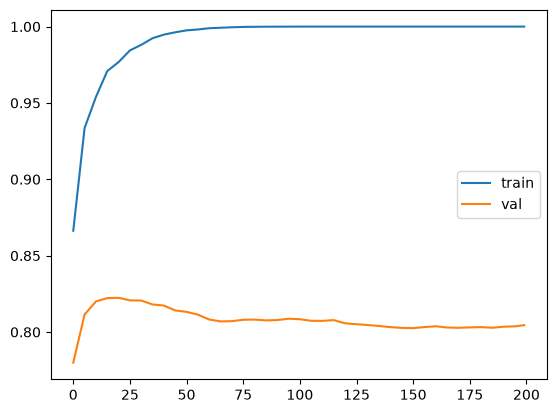

In [141]:
df_score = parse_xgb_output(output)

plt.plot(df_score.num_iter, df_score.train_auc, label='train')
plt.plot(df_score.num_iter, df_score.val_auc, label='val')
plt.legend()

### Tuning eta

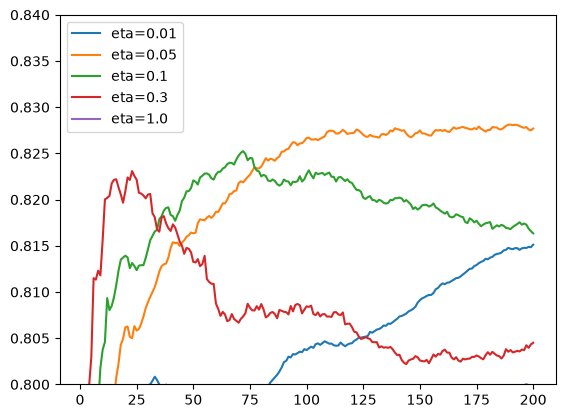

In [148]:
# 1. Reset the scores dictionary
scores = {} 

# 2. Define the list of eta values you want to test
etas = [0.01, 0.05, 0.1, 0.3, 1.0]

# 3. Loop through each eta, train, and store the results
for eta in etas:
    evals_result = {}
    
    xgb_params = {
        'eta': eta,
        'max_depth': 6,
        'min_child_weight': 1,
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }
    
    model = xgb.train(
        xgb_params, 
        dtrain, 
        evals=watchlist, 
        verbose_eval=0, 
        num_boost_round=200, 
        evals_result=evals_result
    )
    
    # Extract metrics using evals_result (cleaner alternative to text parsing)
    columns = ['iter', 'train_auc', 'val_auc']
    train_aucs = list(evals_result['train'].values())[0]
    val_aucs = list(evals_result['val'].values())[0]
    
    df_results = pd.DataFrame(
        list(zip(range(1, len(train_aucs) + 1), train_aucs, val_aucs)), 
        columns=columns
    )
    
    # Save with a unique key for each eta
    key = f'eta={eta}'
    scores[key] = df_results

# 4. Plot all the curves together
for key, df_score in scores.items():
    plt.plot(df_score.iter, df_score.val_auc, label=key)

plt.ylim(0.8, 0.84)
plt.legend()

### Tuning max_depth

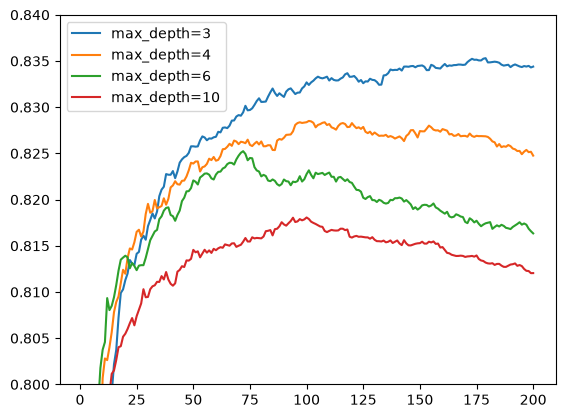

In [150]:
# 1. Reset the scores dictionary for max_depth tuning
scores = {} 

# 2. Define the list of max_depth values you want to test
depths = [3, 4, 6, 10]

# 3. Loop through each depth, train, and store the results
for depth in depths:
    evals_result = {}
    
    xgb_params = {
        'eta': 0.1,  # Keep the best eta we found from the previous step
        'max_depth': depth,
        'min_child_weight': 1,
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }
    
    model = xgb.train(
        xgb_params, 
        dtrain, 
        evals=watchlist, 
        verbose_eval=0, 
        num_boost_round=200, 
        evals_result=evals_result
    )
    
    # Extract metrics using evals_result
    columns = ['iter', 'train_auc', 'val_auc']
    train_aucs = list(evals_result['train'].values())[0]
    val_aucs = list(evals_result['val'].values())[0]
    
    df_results = pd.DataFrame(
        list(zip(range(1, len(train_aucs) + 1), train_aucs, val_aucs)), 
        columns=columns
    )
    
    # Save with a unique key for each max_depth
    key = f'max_depth={depth}'
    scores[key] = df_results

# 4. Plot all the max_depth curves together
for key, df_score in scores.items():
    plt.plot(df_score.iter, df_score.val_auc, label=key)

plt.ylim(0.8, 0.84)
plt.legend()

### Tuning min_child_weight

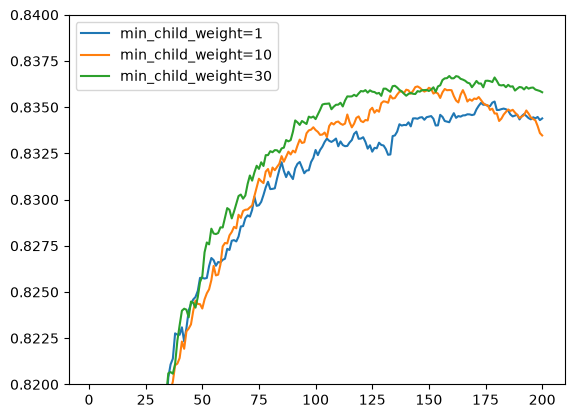

In [152]:
# 1. Reset the scores dictionary for min_child_weight tuning
scores = {} 

# 2. Define the list of min_child_weight values you want to test
min_child_weights = [1, 10, 30]

# 3. Loop through each weight, train, and store the results
for min_child_weight in min_child_weights:
    evals_result = {}
    
    xgb_params = {
        'eta': 0.1,                  # Best eta found previously
        'max_depth': 3,              # Best max_depth found previously
        'min_child_weight': min_child_weight,
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }
    
    model = xgb.train(
        xgb_params, 
        dtrain, 
        evals=watchlist, 
        verbose_eval=0, 
        num_boost_round=200, 
        evals_result=evals_result
    )
    
    # Extract metrics using evals_result
    columns = ['iter', 'train_auc', 'val_auc']
    train_aucs = list(evals_result['train'].values())[0]
    val_aucs = list(evals_result['val'].values())[0]
    
    df_results = pd.DataFrame(
        list(zip(range(1, len(train_aucs) + 1), train_aucs, val_aucs)), 
        columns=columns
    )
    
    # Save with a unique key for each min_child_weight
    key = f'min_child_weight={min_child_weight}'
    scores[key] = df_results

# 4. Plot all the min_child_weight curves together
for key, df_score in scores.items():
    plt.plot(df_score.iter, df_score.val_auc, label=key)

plt.ylim(0.82, 0.84)
plt.legend()

### XGBoost final model with the best hyperparameters

In [154]:
xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=175)

# The winner is XGBoost model

In [160]:
# Decision Tree

dt = DecisionTreeClassifier(max_depth=4)
dt.fit(X_train, y_train)

y_pred = dt.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.7612827250490422

In [161]:
# Random Forest 

rf = RandomForestClassifier(n_estimators=200,
                            max_depth=10,
                            min_samples_leaf=3,
                            random_state=1)
rf.fit(X_train, y_train)

y_pred = rf.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.8246258264512848

In [163]:
# XGBoost 

xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=175)

y_pred = model.predict(dval)
roc_auc_score(y_val, y_pred)

0.8351426460972124

# Training the final model

In [165]:
df_full_train = df_full_train.reset_index(drop=True)

y_full_train = (df_full_train.status == 'default').astype(int).values
del df_full_train['status']

In [166]:
dicts_full_train = df_full_train.to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(dicts_full_train)

dicts_test = df_test.to_dict(orient='records')
X_test = dv.transform(dicts_test)

In [170]:
features = list(dv.get_feature_names_out())


dfulltrain = xgb.DMatrix(X_full_train, label=y_full_train,
                    feature_names=features)

dtest = xgb.DMatrix(X_test, feature_names=features) 

In [171]:
xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dfulltrain, num_boost_round=175)

In [172]:
y_pred = model.predict(dtest)
roc_auc_score(y_test, y_pred)

0.8290589414007137